# Actividad 4. Más allá de las mediciones: dimensiones latentes del perfil cardiometabólico en NHANES

**Técnicas de Análisis No Supervisado** · Especialización en Análisis Estadístico para Ciencia de Datos · Universidad de La Salle

## 1. Configuración

In [1]:
import os
import sys

# Configuración para Google Colab: clona el repositorio, instala dependencias y descarga los datos.
# En una ejecución local esta celda no hace nada.
if "google.colab" in sys.modules:
    if not os.path.exists("/content/nhanes-no-supervisado"):
        !git clone https://github.com/Juanhv24/nhanes-no-supervisado.git /content/nhanes-no-supervisado
    %cd /content/nhanes-no-supervisado
    !pip install -q -e .
    !python scripts/descargar_datos.py
    # Garantiza que el kernel encuentre el paquete aunque no se reinicie la sesión
    sys.path.insert(0, "/content/nhanes-no-supervisado/src")

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from nhanes_no_supervisado.config import SEMILLA, ruta_figuras
from nhanes_no_supervisado.datos import cargar_crudos
from nhanes_no_supervisado.factorial import (
    diagnostico, parallel_analysis, pca_loadings, paf, varimax, promax, reflect_factors,
    comunalidades, rmsr, cronbach_alpha, alpha_if_dropped, item_total_corr, congruencia,
    plot_corr, plot_scree, plot_loadings, tabla_cargas,
)

RUTA_FIGURAS = ruta_figuras(4)

## 2. Problema y contexto

### 2.1 Pregunta guía y relevancia

Los factores de riesgo cardiometabólico no suelen presentarse de forma aislada, sino que tienden a coexistir en una misma persona; de hecho, el síndrome metabólico se define precisamente como la agrupación de obesidad abdominal, presión arterial elevada, triglicéridos elevados, colesterol HDL bajo y glucosa elevada (Alberti et al., 2009). En esta línea, al aplicar el análisis factorial a estas mediciones en el estudio Framingham Offspring, Meigs et al. (1997) encontraron que no varían de forma independiente, sino que se organizan en un número reducido de dimensiones subyacentes. Por otra parte, la literatura ha vinculado este perfil con marcadores que van más allá de sus componentes clásicos, como la proteína C reactiva de alta sensibilidad, que aporta información pronóstica adicional a la del síndrome metabólico (Ridker et al., 2003), y las enzimas hepáticas, dado que el hígado graso no alcohólico se asocia estrechamente con dicho síndrome (Marchesini et al., 2003).

Conocer estas dimensiones es relevante para la identificación temprana y la prevención, más aún si se tiene en cuenta que varias de estas alteraciones avanzan de forma silenciosa: casi la mitad de las personas con hipertensión desconoce que la padece (Organización Mundial de la Salud [OMS], 2023), y por ello se recomienda el tamizaje de la diabetes en adultos sin síntomas que presentan factores de riesgo (American Diabetes Association Professional Practice Committee [ADA], 2025). Así, si bien la evaluación conjunta de los marcadores ofrece una visión general del estado de salud, distinguir sus dimensiones permite reconocer en qué componente se concentra el riesgo de cada persona y, en consecuencia, caracterizar su perfil de forma más específica. A partir de lo anterior, la pregunta guía de esta actividad es: *¿Qué dimensiones latentes resumen el perfil cardiometabólico de los adultos?*

Dado que los marcadores son variables cuantitativas continuas que se espera estén correlacionadas entre sí, el análisis factorial resulta adecuado para responderla, puesto que busca explicar las correlaciones observadas a partir de un número menor de factores latentes que no se miden directamente (Fabrigar et al., 1999).

### 2.2 Base de datos

La Encuesta Nacional de Examen de Salud y Nutrición (NHANES, por sus siglas en inglés) es un programa del Centro Nacional de Estadísticas de Salud (NCHS) de los Centros para el Control y la Prevención de Enfermedades (CDC) de Estados Unidos, diseñado para evaluar el estado de salud y nutrición de su población (National Center for Health Statistics [NCHS], s.f.). La encuesta combina entrevistas en el hogar con exámenes físicos y pruebas de laboratorio, de modo que reúne en un mismo participante características sociodemográficas, hábitos y mediciones clínicas; además, se publica en ciclos de dos años divididos en módulos que se vinculan mediante un identificador único por participante (`SEQN`) (NCHS, s.f.).

En este trabajo se emplea el ciclo 2017–2018, el mismo de las actividades anteriores, al que se suman cuatro módulos de laboratorio: insulina, colesterol total, perfil bioquímico estándar, del que se toman la alanina aminotransferasa (ALT), la gamma-glutamil transferasa (GGT) y el ácido úrico, y proteína C reactiva de alta sensibilidad. Estos se combinan con los módulos ya utilizados de demografía, medidas corporales (circunferencia de cintura e índice de masa corporal), presión arterial, hemoglobina glicada, glucosa en ayunas, triglicéridos y colesterol HDL. Cabe señalar que la insulina, la glucosa y los triglicéridos se miden solo en una submuestra en ayunas de los participantes examinados en la sesión de la mañana (NCHS, 2020c), por lo que el análisis se restringe a esa submuestra.

## 3. Población de estudio

### 3.1 Carga y unión de los módulos

In [3]:
df = cargar_crudos()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9254 entries, 93703 to 102956
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad                   9254 non-null   float64
 1   sexo                   9254 non-null   float64
 2   embarazo               1110 non-null   float64
 3   educacion              5569 non-null   float64
 4   raza_etnia             9254 non-null   float64
 5   ingreso_pobreza        8023 non-null   float64
 6   cintura_cm             7601 non-null   float64
 7   imc                    8005 non-null   float64
 8   hba1c_pct              6045 non-null   float64
 9   glucosa_mgdl           2891 non-null   float64
 10  peso_ayuno             3036 non-null   float64
 11  trigliceridos_mgdl     2834 non-null   float64
 12  hdl_mgdl               6738 non-null   float64
 13  diabetes_dx            8897 non-null   float64
 14  fumo_100               5856 non-null   float64
 15  fuma_actu

### 3.2 Selección de la población

In [4]:
# Adultos de 20 años o más, sin embarazo confirmado y de la submuestra en ayunas
es_adulto = df["edad"] >= 20
es_embarazada = df["embarazo"] == 1
submuestra = df["peso_ayuno"] > 0

df_poblacion = df[es_adulto & ~es_embarazada & submuestra].drop(columns="embarazo")

print(f"El DataFrame de población cuenta con {df_poblacion.shape[0]} filas y {df_poblacion.shape[1]} columnas")

El DataFrame de población cuenta con 2279 filas y 25 columnas


La población de estudio se restringe a adultos de 20 años o más, que es el corte habitual en los estudios sobre salud cardiometabólica basados en NHANES (Hirode & Wong, 2020), y se excluyen las participantes con embarazo confirmado, puesto que la gestación modifica de forma marcada el perfil metabólico (Wang et al., 2016). Además, a diferencia de la actividad anterior, en la que bastaba con disponer de la HbA1c, en este caso se conservan solo los participantes de la submuestra en ayunas, identificados por un peso muestral de ayuno mayor que cero, ya que la insulina, la glucosa y los triglicéridos únicamente se miden en ella (NCHS, 2020c). Como resultado, la población de estudio queda conformada por 2.279 adultos.

### 3.3 Selección de variables

In [5]:
VARIABLES_AF = ["cintura_cm", "imc", "sistolica_mmhg", "diastolica_mmhg", "hba1c_pct",
                "glucosa_mgdl", "insulina_uuml", "trigliceridos_mgdl", "hdl_mgdl",
                "colesterol_total_mgdl", "alt_ul", "ggt_ul", "acido_urico_mgdl", "pcr_mgl"]

# Faltantes por variable antes de excluir 
print(df_poblacion[VARIABLES_AF].isna().sum().sort_values(ascending=False))

df_af = df_poblacion[VARIABLES_AF].dropna()
print(f"Participantes con todas las variables: {len(df_af)} de {len(df_poblacion)}")

diastolica_mmhg          104
cintura_cm               103
sistolica_mmhg            99
pcr_mgl                   48
acido_urico_mgdl          46
alt_ul                    45
ggt_ul                    45
insulina_uuml             44
imc                       37
colesterol_total_mgdl     37
trigliceridos_mgdl        37
hdl_mgdl                  37
hba1c_pct                  3
glucosa_mgdl               0
dtype: int64
Participantes con todas las variables: 2043 de 2279


In [6]:
# Medianas de los participantes incluidos y de los excluidos por datos faltantes
excluidos = df_poblacion.loc[~df_poblacion.index.isin(df_af.index)]
comparacion_exclusion = pd.DataFrame({
    "Incluidos": df_poblacion.loc[df_af.index, ["edad", *VARIABLES_AF]].median(),
    "Excluidos": excluidos[["edad", *VARIABLES_AF]].median(),
})
display(comparacion_exclusion.round(1))

,Incluidos,Excluidos
edad,53.0,54.0
cintura_cm,99.2,98.6
imc,28.5,28.7
sistolica_mmhg,123.3,128.0
diastolica_mmhg,72.7,72.3
hba1c_pct,5.6,5.7
glucosa_mgdl,104.0,104.0
insulina_uuml,9.9,10.6
trigliceridos_mgdl,94.0,92.0
hdl_mgdl,51.0,52.0


Del total de la población, 236 participantes (10,4 %) carecen de al menos una de las catorce variables, principalmente de la presión arterial y la circunferencia de cintura, que se registran en el examen físico, y en menor medida de alguna prueba de laboratorio. Dado que el análisis factorial parte de una única matriz de correlaciones, en la que todos los coeficientes deben calcularse sobre los mismos participantes, se conservan solo los casos completos (Tabachnick & Fidell, 2019), de modo que la muestra analítica queda conformada por 2.043 adultos. Asimismo, las medianas de los excluidos son cercanas a las de los incluidos, tanto en la edad como en los marcadores, con diferencias de pocas unidades, por lo que la exclusión no parece introducir un sesgo de selección relevante.

### 3.4 Clasificación de variables

| Variable | Código NHANES | Módulo | Tipo | Subtipo | Unidad | Rol | Descripción |
|---|---|---|---|---|---|---|---|
| `cintura_cm` | BMXWAIST | BMX | Cuantitativa | Continua de razón | cm | Activa | Indicador de obesidad abdominal, componente del síndrome metabólico |
| `imc` | BMXBMI | BMX | Cuantitativa | Continua de razón | kg/m² | Excluida | Indicador de adiposidad general; se retira por su redundancia con la cintura (sección 4.2) |
| `sistolica_mmhg` | BPXSY1–BPXSY4 | BPX | Cuantitativa | Continua de razón | mmHg | Activa | Promedio de las lecturas disponibles (hasta cuatro) |
| `diastolica_mmhg` | BPXDI1–BPXDI4 | BPX | Cuantitativa | Continua de razón | mmHg | Activa | Promedio de las lecturas disponibles; las lecturas de 0 mmHg se tratan como faltantes |
| `hba1c_pct` | LBXGH | GHB | Cuantitativa | Continua de razón | % | Activa | Refleja la glucemia promedio de los últimos dos a tres meses; no requiere ayuno |
| `glucosa_mgdl` | LBXGLU | GLU | Cuantitativa | Continua de razón | mg/dL | Activa | Glucosa plasmática en ayunas |
| `insulina_uuml` | LBXIN | INS | Cuantitativa | Continua de razón | µU/mL | Activa | Insulina en ayunas, medida en la misma submuestra que la glucosa |
| `trigliceridos_mgdl` | LBXTR | TRIGLY | Cuantitativa | Continua de razón | mg/dL | Activa | Se mide en ayunas; componente del síndrome metabólico |
| `hdl_mgdl` | LBDHDD | HDL | Cuantitativa | Continua de razón | mg/dL | Activa | Único marcador protector: valores más altos indican menor riesgo |
| `colesterol_total_mgdl` | LBXTC | TCHOL | Cuantitativa | Continua de razón | mg/dL | Excluida | Colesterol total; no forma parte de los criterios del síndrome metabólico y se retira por su MSA (sección 4.1) |
| `alt_ul` | LBXSATSI | BIOPRO | Cuantitativa | Continua de razón | U/L | Activa | Alanina aminotransferasa, enzima hepática asociada con el hígado graso |
| `ggt_ul` | LBXSGTSI | BIOPRO | Cuantitativa | Continua de razón | U/L | Activa | Gamma-glutamil transferasa, enzima hepática |
| `acido_urico_mgdl` | LBXSUA | BIOPRO | Cuantitativa | Continua de razón | mg/dL | Activa | Producto final del metabolismo de las purinas |
| `pcr_mgl` | LBXHSCRP | HSCRP | Cuantitativa | Continua de razón | mg/L | Activa | Marcador de inflamación sistémica; los valores bajo el límite de detección (0,15 mg/L) vienen imputados como 0,11 mg/L |
| `edad` | RIDAGEYR | DEMO | Cuantitativa | Discreta | años | Filtro y validación | Edad en años cumplidos; NHANES registra como 80 a todos los mayores de 80 años |
| `embarazo` | RIDEXPRG | DEMO | Cualitativa | Nominal | 1 = sí, 2 = no, 3 = no determinado | Filtro | Se excluyen las participantes con embarazo confirmado |
| `peso_ayuno` | WTSAF2YR | GLU | Cuantitativa | Continua | — | Filtro | Peso muestral de la submuestra en ayunas; vale 0 para quienes no pertenecen a ella |
| `diabetes_dx` | DIQ010 | DIQ | Cualitativa | Nominal | 1 = sí, 2 = no, 3 = limítrofe, 7 = se negó, 9 = no sabe | Validación externa | Diagnóstico médico autorreportado; no entra en el análisis factorial |

Las descripciones de la tabla se basan en la documentación del ciclo 2017–2018 (NCHS, 2020a, 2020b, 2020c), en los criterios del síndrome metabólico (Alberti et al., 2009) y en la asociación entre las enzimas hepáticas y el hígado graso (Marchesini et al., 2003). En consecuencia, el análisis factorial parte de las catorce variables cuantitativas continuas, de las cuales dos se retiran en la revisión de los supuestos, mientras que la edad, el embarazo y el peso muestral de ayuno sirven para delimitar la población, y el diagnóstico de diabetes se reserva para la validación externa. Además, la tabla anticipa dos aspectos que condicionan las decisiones posteriores: la redundancia entre la cintura y el IMC, que lleva a retirar el IMC, y el sentido inverso del HDL respecto al riesgo, que hará que cargue con signo contrario al de las demás variables de su factor.

### 3.5 Descriptivos y distribuciones

In [7]:
def describir_extendido(data):
    """Agrega asimetría y coeficiente de variación al describe() de pandas."""
    descripcion = data.describe()
    extra = pd.DataFrame(
        [data.skew(), data.std() / data.mean()],
        index=["asimetria", "cv"],
    )
    return pd.concat([descripcion, extra])


descripcion = describir_extendido(df_af).T.sort_values("asimetria", ascending=False)
display(descripcion.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetria,cv
insulina_uuml,2043.0,14.14,19.61,0.71,6.21,9.89,16.05,485.10,10.90,1.39
pcr_mgl,2043.0,4.17,8.16,0.11,0.87,1.97,4.31,138.81,7.37,1.96
trigliceridos_mgdl,2043.0,113.38,90.63,10.00,62.00,94.00,137.50,1479.00,5.78,0.80
ggt_ul,2043.0,31.55,36.68,4.00,15.00,21.00,33.00,414.00,5.02,1.16
glucosa_mgdl,2043.0,114.47,37.53,47.00,97.00,104.00,116.00,451.00,3.87,0.33
alt_ul,2043.0,22.38,16.09,3.00,13.00,18.00,25.50,181.00,3.33,0.72
hba1c_pct,2043.0,5.88,1.13,4.10,5.30,5.60,6.00,15.20,3.15,0.19
hdl_mgdl,2043.0,53.38,15.59,11.00,42.00,51.00,61.00,178.00,1.39,0.29
imc,2043.0,29.73,7.12,15.50,24.70,28.50,33.50,65.30,1.11,0.24
sistolica_mmhg,2043.0,126.42,19.90,74.00,112.67,123.33,136.67,218.00,0.97,0.16


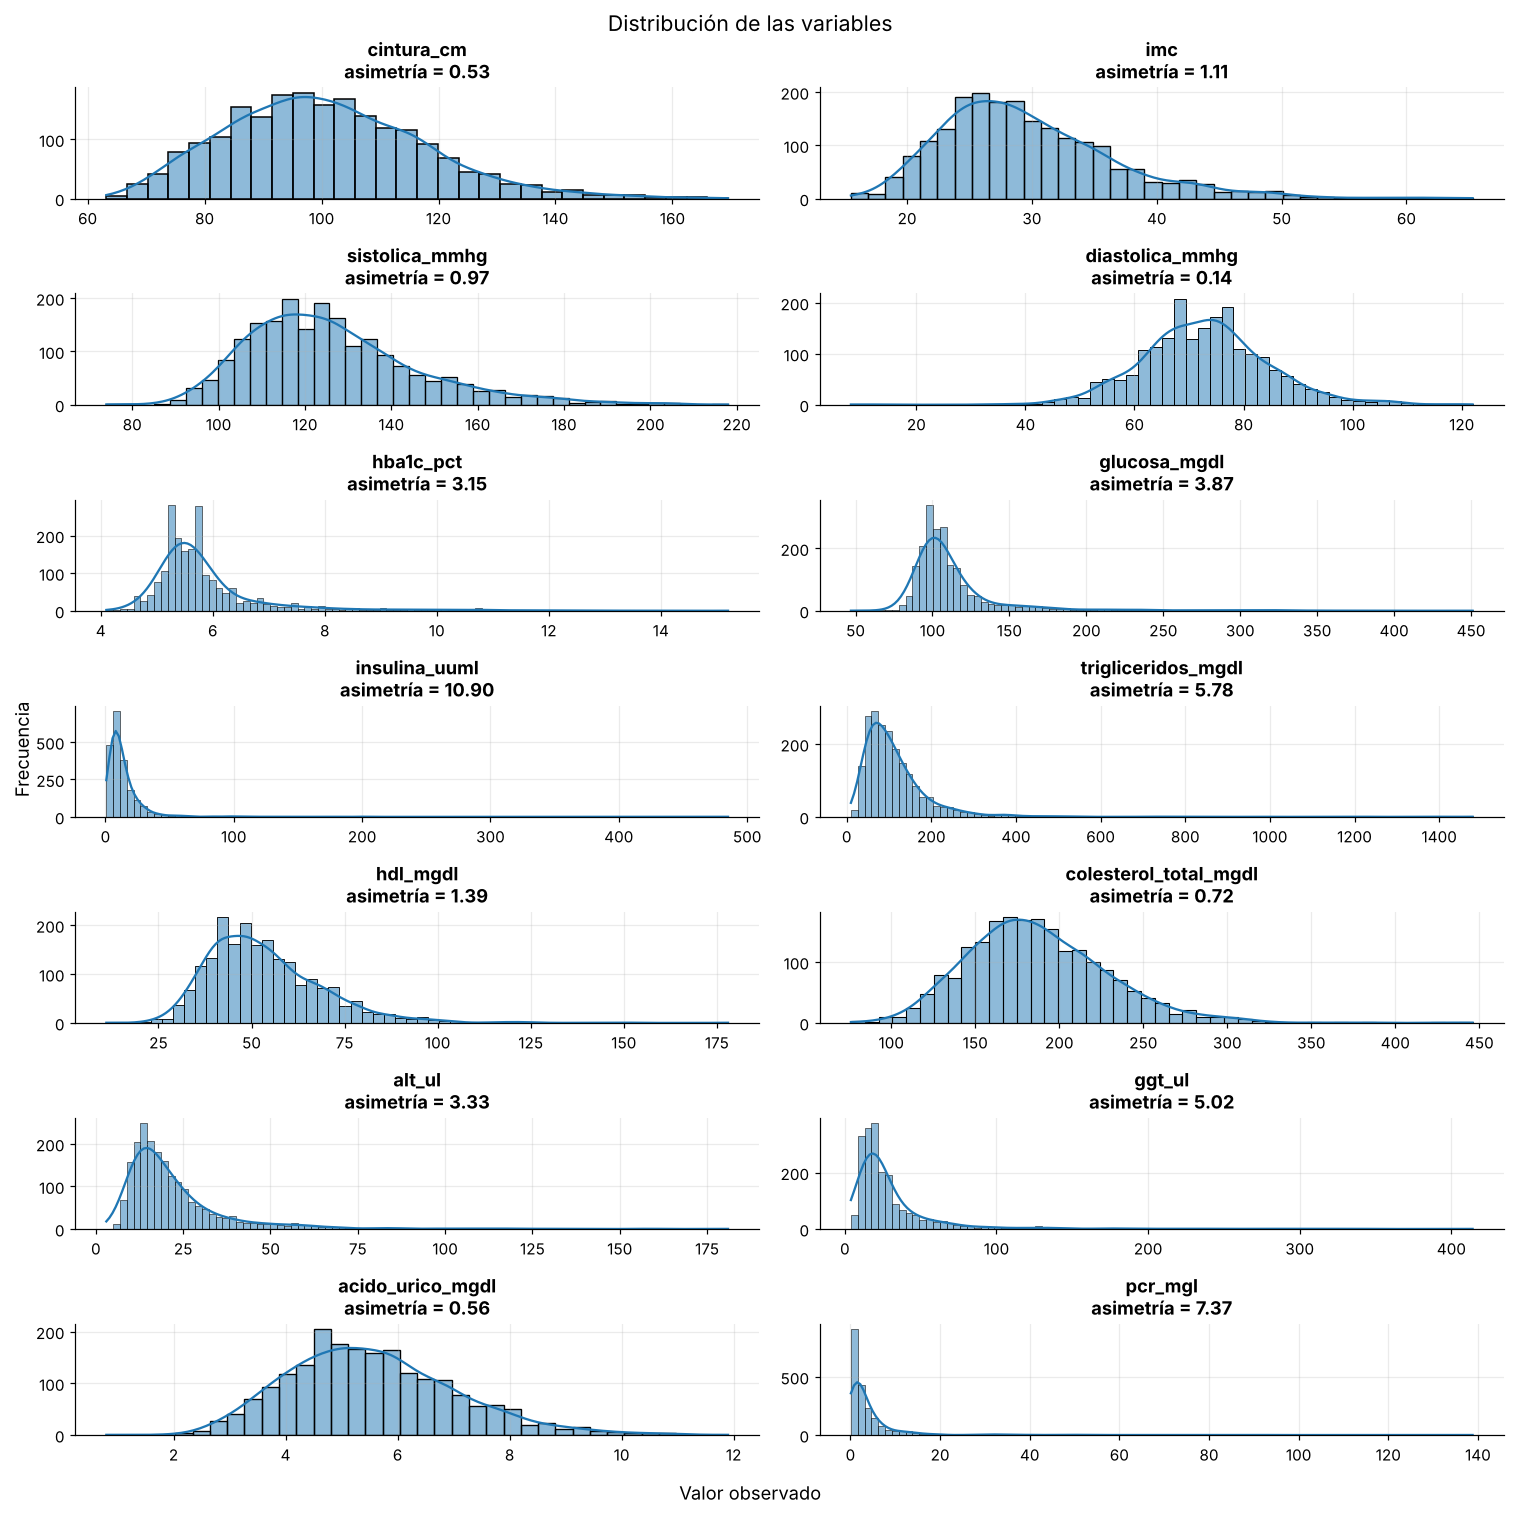

In [8]:
fig, axs = plt.subplots(7, 2, figsize=(14, 14))

for ax, columna in zip(axs.ravel(), df_af.columns):
    valores = df_af[columna]
    sns.histplot(valores, kde=True, ax=ax)
    ax.set(title=f"{columna}\nasimetría = {valores.skew():.2f}", xlabel="", ylabel="")

fig.suptitle("Distribución de las variables", fontsize=14)
fig.supxlabel("Valor observado")
fig.supylabel("Frecuencia")
fig.tight_layout()
plt.show()

Los descriptivos muestran que las variables se encuentran en escalas muy distintas, desde la HbA1c, con valores cercanos al 6 %, hasta los triglicéridos, que alcanzan cientos de mg/dL; sin embargo, esto no afecta al análisis, puesto que se basa en la matriz de correlaciones, que no depende de las unidades de medida. Por el contrario, varias variables presentan una asimetría positiva marcada, en especial la insulina (10,90), la PCR (7,37), los triglicéridos (5,78) y la GGT (5,02), cuyas colas derechas corresponden a participantes con valores muy elevados. De forma similar, la glucosa (3,87) y la HbA1c (3,15) muestran una cola derecha que coincide con los valores en rango de diabetes.

En cuanto a los valores extremos, se identifican dos casos particulares. Por un lado, 173 participantes (8,5 %) tienen una PCR mayor que 10 mg/L, un nivel ante el cual la declaración de la American Heart Association y los CDC recomienda buscar una infección o inflamación aguda y repetir la medición (Pearson et al., 2003); sin embargo, NHANES ofrece una sola medición por participante, por lo que no es posible distinguir estos casos de una inflamación persistente, y se opta por conservarlos y atenuar su influencia mediante la transformación logarítmica. Por otro lado, la presión diastólica registra dos valores inferiores a 20 mmHg (8 y 12 mmHg), poco plausibles, aunque su efecto sobre las correlaciones es mínimo dado el tamaño de la muestra.

### 3.6 Transformación logarítmica

In [9]:
# Se transforman con logaritmo natural las variables con asimetría mayor que 1;
# todas son estrictamente positivas, por lo que el logaritmo está definido
asimetria = df_af.skew()
VARIABLES_LOG = asimetria[asimetria > 1].index.tolist()

df_af_log = df_af.copy()
df_af_log[VARIABLES_LOG] = np.log(df_af_log[VARIABLES_LOG])

comparacion_asimetria = pd.DataFrame({
    "Original": asimetria[VARIABLES_LOG],
    "Logaritmo": df_af_log[VARIABLES_LOG].skew(),
}).sort_values("Original", ascending=False)
display(comparacion_asimetria.round(2))

,Original,Logaritmo
insulina_uuml,10.90,0.39
pcr_mgl,7.37,0.37
trigliceridos_mgdl,5.78,0.32
ggt_ul,5.02,1.00
glucosa_mgdl,3.87,2.28
alt_ul,3.33,0.67
hba1c_pct,3.15,2.13
hdl_mgdl,1.39,0.18
imc,1.11,0.36


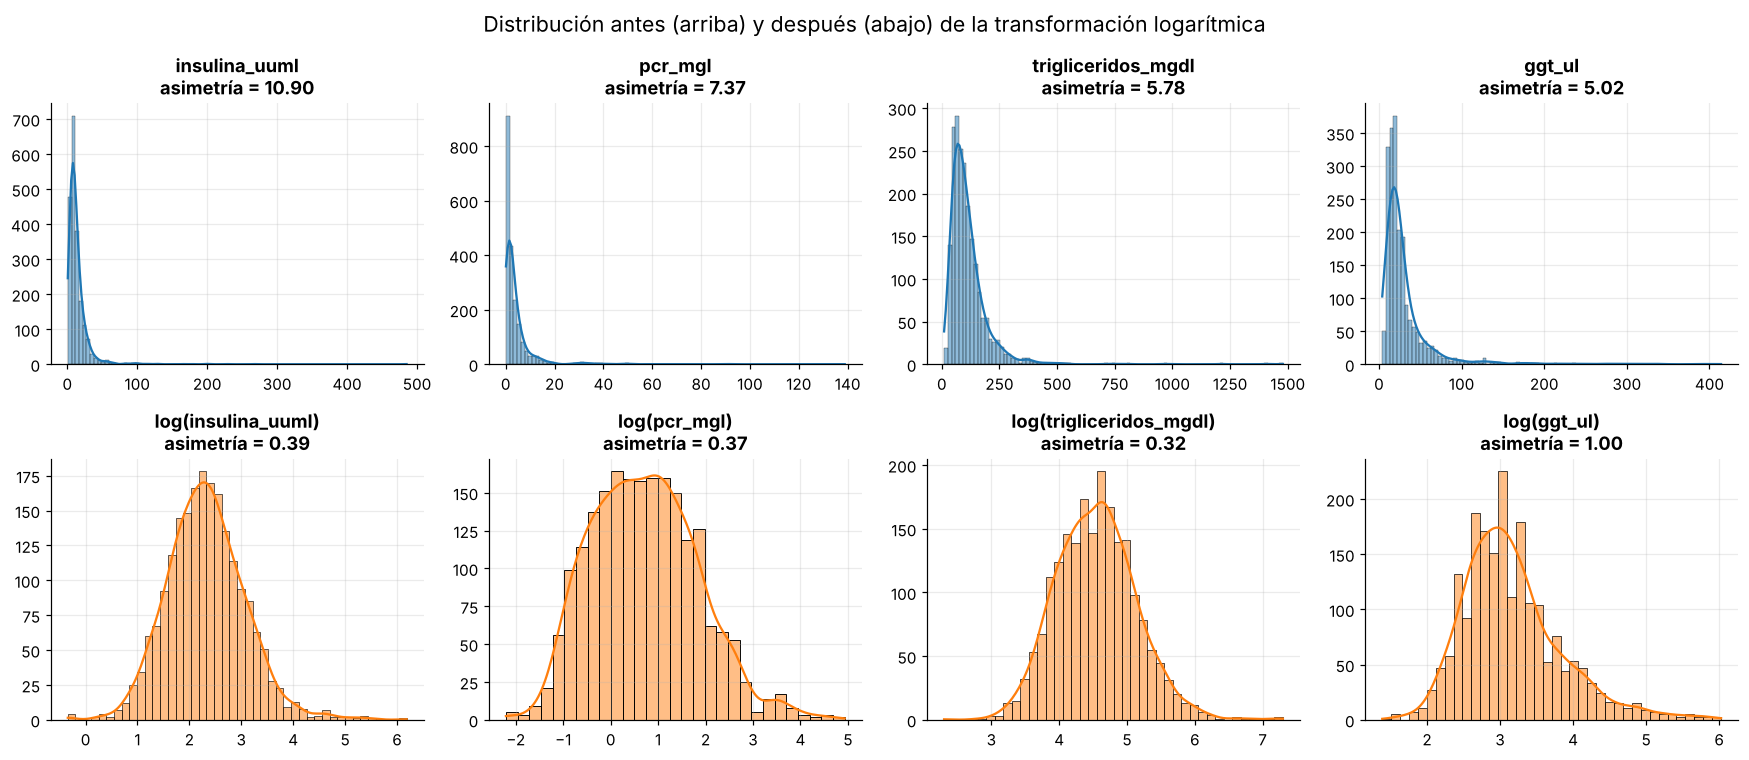

In [10]:
# Distribución de las cuatro variables más asimétricas antes y después de la transformación
MAS_ASIMETRICAS = comparacion_asimetria.index[:4]

fig, axs = plt.subplots(2, 4, figsize=(16, 7))

for j, columna in enumerate(MAS_ASIMETRICAS):
    sns.histplot(df_af[columna], kde=True, ax=axs[0, j])
    axs[0, j].set(title=f"{columna}\nasimetría = {df_af[columna].skew():.2f}", xlabel="", ylabel="")
    sns.histplot(df_af_log[columna], kde=True, color="tab:orange", ax=axs[1, j])
    axs[1, j].set(title=f"log({columna})\nasimetría = {df_af_log[columna].skew():.2f}", xlabel="", ylabel="")

fig.suptitle("Distribución antes (arriba) y después (abajo) de la transformación logarítmica", fontsize=14)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_transformacion.png", dpi=150, bbox_inches="tight")
plt.show()

Se adopta como criterio transformar con el logaritmo natural las variables con asimetría mayor que 1, lo que incluye nueve de las catorce: insulina, PCR, triglicéridos, GGT, glucosa, ALT, HbA1c, HDL e IMC. Si bien la extracción por ejes principales no exige normalidad multivariada (Fabrigar et al., 1999), la correlación de Pearson, sobre la que se construye todo el análisis, es sensible a la asimetría y a los valores extremos, y la transformación logarítmica es una de las alternativas recomendadas para corregir la asimetría positiva (Tabachnick & Fidell, 2019). Como resultado, la asimetría de la insulina, la PCR y los triglicéridos desciende por debajo de 0,40, y la de la GGT pasa de 5,02 a 1,00. En cambio, la glucosa (2,28) y la HbA1c (2,13) conservan una asimetría importante, lo que es coherente con la presencia de participantes con valores en rango de diabetes, que forman un grupo diferenciado en la cola derecha. Por consiguiente, el resto del análisis se realiza sobre las variables transformadas (`df_af_log`).

## 4. Pertinencia y supuestos

### 4.1 Matriz de correlación y mapa de calor

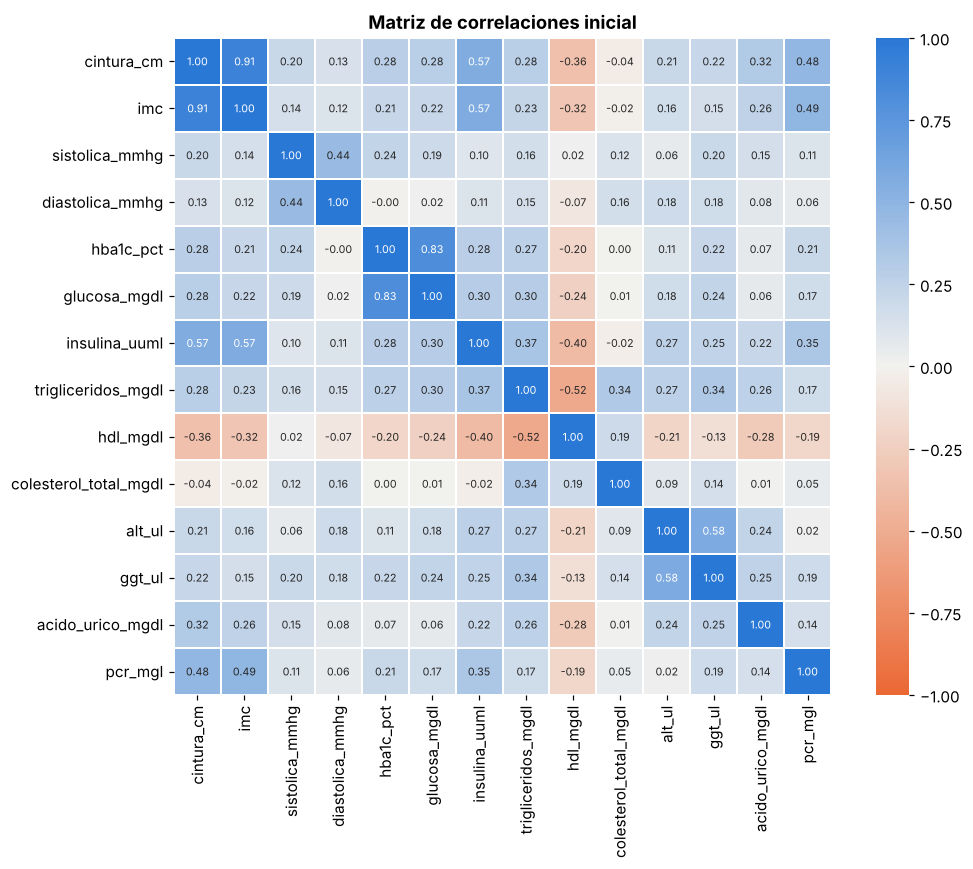

n                        2,043.0000
p                           14.0000
n/p                        145.9286
% pares |r|>0.30            19.7802
max |r|                      0.9112
determinante                 0.0022
KMO global                   0.6884
MSA mínimo                   0.3195
Bartlett chi2           12,468.3472
gl                          91.0000
p-valor                      0.0000
autovalor mínimo de R        0.0799

Calidad del KMO global: aceptable

MSA por variable:
 cintura_cm               0.72
imc                      0.69
sistolica_mmhg           0.61
diastolica_mmhg          0.59
hba1c_pct                0.63
glucosa_mgdl             0.65
insulina_uuml            0.94
trigliceridos_mgdl       0.65
hdl_mgdl                 0.63
colesterol_total_mgdl    0.32
alt_ul                   0.66
ggt_ul                   0.69
acido_urico_mgdl         0.86
pcr_mgl                  0.87


In [11]:
R_inicial = df_af_log.corr()
plot_corr(R_inicial, "Matriz de correlaciones inicial", annot=True, figsize=(10, 8),
          ruta=RUTA_FIGURAS / "02_correlaciones_inicial.png")

info_inicial, msa_inicial = diagnostico(R_inicial.values, n=len(df_af_log), nombres=df_af_log.columns)
print("\nMSA por variable:\n", msa_inicial.round(2).to_string())

La matriz de correlaciones muestra que el 19,8 % de los pares de variables supera |r| = 0,30, lo que indica que existen relaciones suficientes para buscar factores comunes. En la misma línea, la prueba de esfericidad de Bartlett rechaza que la matriz sea una identidad (χ² = 12.468,35; gl = 91; p < 0,001), aunque con una muestra de este tamaño la prueba rechaza casi siempre, por lo que el KMO resulta más informativo (Tabachnick & Fidell, 2019). En este caso, el KMO global es de 0,69, un valor aceptable aunque modesto, que se ubica en el rango de 0,60 a 0,70 que Kaiser (1974) califica como mediocre.

Sin embargo, el MSA por variable muestra que el colesterol total (0,32) no alcanza el mínimo de 0,50 (Kaiser, 1974), es decir, comparte muy poca varianza con las demás variables; de hecho, su correlación más alta es con los triglicéridos (r = 0,34) y con el resto no supera 0,20. Por esta razón, se retira del análisis. Además, la matriz revela una correlación de 0,91 entre la cintura y el IMC, que se revisa en la depuración.

### 4.2 Depuración de variables

In [12]:
# Se retira el colesterol total (MSA < 0,50) y se revisan los pares con |r| > 0,85
VARIABLES_SIN_COLESTEROL = [v for v in df_af_log.columns if v != "colesterol_total_mgdl"]
R_sin_colesterol = df_af_log[VARIABLES_SIN_COLESTEROL].corr()

pares = R_sin_colesterol.where(np.triu(np.ones(R_sin_colesterol.shape, dtype=bool), k=1)).stack()
print("Pares con |r| > 0,85:")
print(pares[pares.abs() > 0.85].round(3).to_string())

Pares con |r| > 0,85:
cintura_cm  imc    0.911


Tras retirar el colesterol total, la cintura y el IMC mantienen una correlación de 0,91, un nivel que se considera multicolinealidad (Tabachnick & Fidell, 2019). Dos variables tan redundantes aportan prácticamente la misma información, de modo que tienden a formar entre ellas un factor propio y pueden producir comunalidades iguales o superiores a 1 (casos Heywood). Por ello, se conserva solo la circunferencia de cintura, ya que es el indicador de obesidad abdominal que forma parte de los criterios del síndrome metabólico (Alberti et al., 2009) y, además, presenta un MSA mayor que el del IMC (0,72 frente a 0,69).

### 4.3 Diagnóstico de la matriz depurada

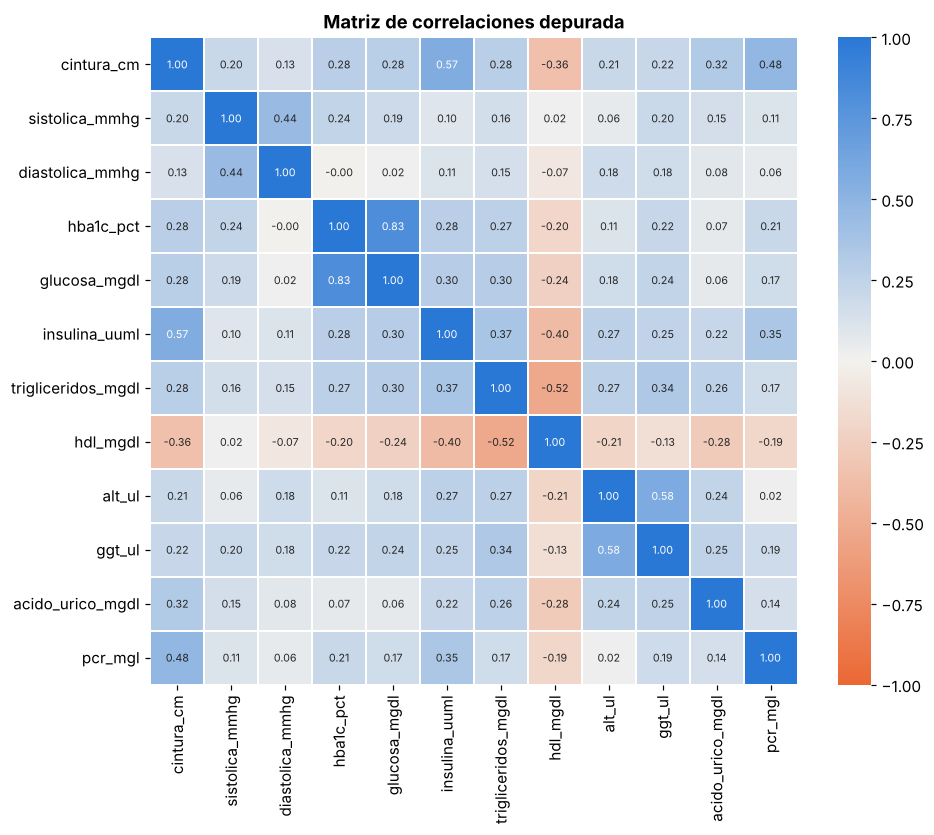

n                       2,043.0000
p                          12.0000
n/p                       170.2500
% pares |r|>0.30           19.6970
max |r|                     0.8260
determinante                0.0210
KMO global                  0.7053
MSA mínimo                  0.5810
Bartlett chi2           7,865.6000
gl                         66.0000
p-valor                     0.0000
autovalor mínimo de R       0.1675

Calidad del KMO global: bueno

MSA por variable:
 cintura_cm            0.77
sistolica_mmhg        0.59
diastolica_mmhg       0.58
hba1c_pct             0.62
glucosa_mgdl          0.64
insulina_uuml         0.84
trigliceridos_mgdl    0.79
hdl_mgdl              0.74
alt_ul                0.65
ggt_ul                0.68
acido_urico_mgdl      0.82
pcr_mgl               0.74


In [13]:
VARIABLES_FINALES = [v for v in VARIABLES_SIN_COLESTEROL if v != "imc"]
df_final = df_af_log[VARIABLES_FINALES]

R = df_final.corr()
plot_corr(R, "Matriz de correlaciones depurada", annot=True, figsize=(9, 7.5),
          ruta=RUTA_FIGURAS / "03_correlaciones_depurada.png")

info, msa = diagnostico(R.values, n=len(df_final), nombres=VARIABLES_FINALES)
print("\nMSA por variable:\n", msa.round(2).to_string())

Con las doce variables restantes, todos los indicadores respaldan la pertinencia del análisis factorial. En primer lugar, el KMO global sube a 0,71, que Kaiser (1974) califica como regular, y el MSA mínimo es de 0,58, correspondiente a la presión diastólica, de modo que todas las variables superan el mínimo de 0,50. En segundo lugar, la prueba de Bartlett sigue siendo significativa (χ² = 7.865,60; gl = 66; p < 0,001) y el 19,7 % de los pares supera |r| = 0,30. En tercer lugar, el determinante (0,021) se aleja de cero y la correlación más alta, entre la HbA1c y la glucosa (r = 0,83), ya no supera el umbral de 0,85, por lo que no hay indicios de multicolinealidad extrema. Por último, la razón de 170 participantes por variable supera ampliamente el mínimo habitual de 10 (Tabachnick & Fidell, 2019). En consecuencia, el análisis continúa con doce variables y 2.043 participantes.

## 5. Número de factores

,Autovalor,Percentil 95 (aleatorio),% varianza,% acumulado
Factor,,,,
1,3.64,1.16,30.37,30.37
2,1.50,1.11,12.53,42.90
3,1.39,1.09,11.57,54.47
4,1.23,1.06,10.26,64.73
5,0.97,1.04,8.09,72.83
6,0.81,1.02,6.73,79.56


Kaiser (autovalor > 1):           4 factores
Análisis paralelo (λ > aleatorio): 4 factores


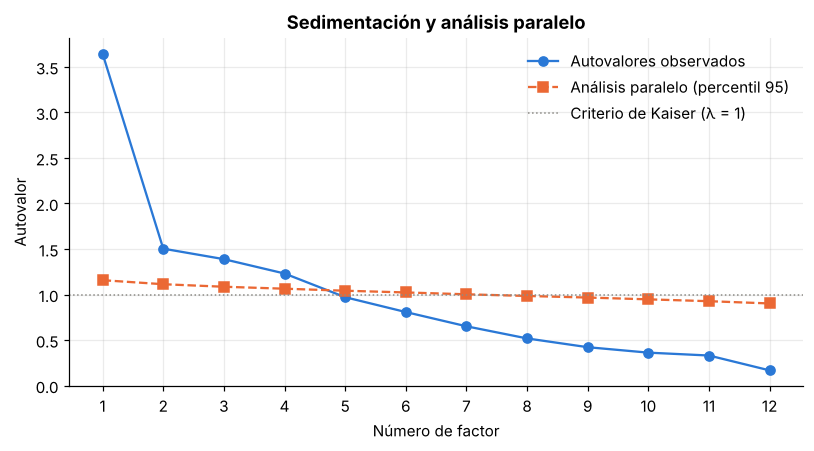

In [14]:
autoval = np.sort(np.linalg.eigvalsh(R.values))[::-1]
paralelo = parallel_analysis(n=len(df_final), p=len(VARIABLES_FINALES), seed=SEMILLA)

tabla = pd.DataFrame({"Autovalor": autoval, "Percentil 95 (aleatorio)": paralelo,
                      "% varianza": 100 * autoval / len(autoval),
                      "% acumulado": 100 * np.cumsum(autoval) / len(autoval)},
                      index=np.arange(1, len(autoval) + 1))
tabla.index.name = "Factor"
display(tabla.head(6).round(2))
print("Kaiser (autovalor > 1):          ", int((autoval > 1).sum()), "factores")
print("Análisis paralelo (λ > aleatorio):", int((autoval > paralelo).sum()), "factores")
plot_scree(autoval, paralelo, "Sedimentación y análisis paralelo",
           ruta=RUTA_FIGURAS / "04_sedimentacion.png")

In [15]:
# Ajuste de la extracción por ejes principales con 1 a 5 factores
ajuste_factores = []
for m in range(1, 6):
    L_m, h2_m, iteraciones = paf(R.values, m)
    ajuste_factores.append({
        "Factores": m,
        "% varianza común": 100 * h2_m.sum() / len(VARIABLES_FINALES),
        "RMSR": rmsr(R.values, L_m),
        "Comunalidad mínima": h2_m.min(),
        "Comunalidad máxima": h2_m.max(),
        "Iteraciones": iteraciones,
    })
display(pd.DataFrame(ajuste_factores).set_index("Factores").round(3))

,% varianza común,RMSR,Comunalidad mínima,Comunalidad máxima,Iteraciones
Factores,,,,,
1,24.502,0.122,0.049,0.422,11
2,35.453,0.092,0.075,1.013,293
3,43.173,0.068,0.097,1.007,358
4,55.868,0.042,0.182,1.461,500
5,64.137,0.018,0.164,1.702,500


Los criterios de retención coinciden en cuatro factores. Por un lado, el criterio de Kaiser retiene los cuatro autovalores mayores que 1 (3,64; 1,50; 1,39 y 1,23); por otro, el análisis paralelo, uno de los procedimientos más precisos para esta decisión (Fabrigar et al., 1999), también retiene cuatro, ya que el quinto autovalor (0,97) queda por debajo del que se obtiene con datos aleatorios (1,04) (Horn, 1965). En conjunto, los cuatro primeros componentes acumulan el 64,73 % de la varianza total. En cambio, el gráfico de sedimentación muestra un codo marcado después del primer autovalor, que concentra por sí solo el 30,37 % de la varianza y sugiere un componente general de riesgo cardiometabólico; no obstante, a partir del segundo los autovalores descienden de forma gradual, de modo que el codo no ofrece un punto de corte claro para los siguientes.

Asimismo, el RMSR disminuye de 0,122 con un factor a 0,042 con cuatro, lo que indica que las correlaciones que reproduce el modelo se acercan a las observadas. Si bien con cinco factores el ajuste mejora aún más, el quinto autovalor no supera el análisis paralelo, por lo que ese factor adicional no se distingue de lo esperable por azar. Por lo tanto, se retiene **m = 4**. Sin embargo, la tabla también muestra que a partir de dos factores la extracción por ejes principales produce comunalidades mayores que 1, conocidas como casos Heywood, que en la solución de cuatro factores alcanzan 1,46; dado que una comunalidad no puede superar la varianza total de la variable, este problema se aborda en la sección de extracción.

## 6. Extracción y rotación

### 6.1 Componentes principales frente a ejes principales

In [16]:
m = 4
L_pca, _ = pca_loadings(R.values, m)
L_paf, h2_paf, iteraciones = paf(R.values, m, cota=1)
print(f"PAF convergió en {iteraciones} iteraciones")

comp = pd.DataFrame({"h² PCA": comunalidades(L_pca), "h² PAF": h2_paf}, index=df_final.columns)
comp["Diferencia"] = comp["h² PCA"] - comp["h² PAF"]
display(comp.round(2))
p = len(VARIABLES_FINALES)
print("Varianza explicada (suma de h² / p): PCA =", round(comp["h² PCA"].sum() / p, 3),
      "| PAF =", round(comp["h² PAF"].sum() / p, 3))

PAF convergió en 213 iteraciones


,h² PCA,h² PAF,Diferencia
cintura_cm,0.69,0.61,0.08
sistolica_mmhg,0.75,1.00,-0.25
diastolica_mmhg,0.67,0.23,0.44
hba1c_pct,0.89,0.86,0.04
glucosa_mgdl,0.89,0.81,0.08
insulina_uuml,0.58,0.49,0.09
trigliceridos_mgdl,0.48,0.34,0.14
hdl_mgdl,0.53,0.35,0.18
alt_ul,0.73,0.66,0.07
ggt_ul,0.66,0.50,0.16


Varianza explicada (suma de h² / p): PCA = 0.647 | PAF = 0.526


Con cuatro factores, la extracción por ejes principales con comunalidades sin acotar no converge y produce casos Heywood (sección 5), por lo que se acotan las comunalidades en 1 en cada iteración, que corresponde a la opción HEYWOOD del procedimiento de análisis factorial de SAS (SAS Institute Inc., 2011). Con esta restricción, la extracción converge en 213 iteraciones.

En once de las doce variables, la comunalidad con componentes principales es mayor que con ejes principales, que es lo esperable, puesto que los componentes principales parten de una diagonal de unos y, por tanto, atribuyen a los componentes toda la varianza de cada variable, incluida la única y el error de medición, mientras que los ejes principales solo modelan la varianza común (Fabrigar et al., 1999). Por ello, la varianza explicada desciende del 64,7 % con componentes principales al 52,6 % con ejes principales, y las mayores diferencias se presentan en las variables que comparten menos varianza con las demás, como la PCR (0,26), el HDL (0,18) y el ácido úrico (0,17), sin contar la diastólica, que se comenta a continuación.

La única excepción es la presión sistólica, cuya comunalidad con ejes principales (1,00) supera a la de componentes principales (0,75). Esto se debe a que, con solo dos indicadores, el factor de presión arterial queda definido casi por completo por la sistólica, cuya comunalidad alcanza el límite, mientras que la diastólica conserva apenas 0,23; en cambio, los componentes principales reparten la varianza entre ambas de forma más equilibrada (0,75 y 0,67). Por lo tanto, la excepción no contradice el patrón general, sino que refleja la debilidad de un factor con solo dos variables, que se tendrá en cuenta al interpretarlo. En consecuencia, se elige la extracción por ejes principales, ya que el objetivo es identificar dimensiones latentes a partir de la varianza que las variables comparten y no simplemente resumir su varianza total (Fabrigar et al., 1999).

### 6.2 Rotación: varimax frente a promax

In [17]:
L_var, T = varimax(L_paf)
L_pro, Phi_pro = promax(L_paf)
L_var = reflect_factors(L_var)
L_pro, Phi_pro = reflect_factors(L_pro, Phi_pro)

print("Correlación entre factores (promax):")
display(pd.DataFrame(Phi_pro, index=["F1", "F2", "F3", "F4"], columns=["F1", "F2", "F3", "F4"]).round(2))

h2_cmp = pd.DataFrame({"Sin rotar": comunalidades(L_paf),
                       "Varimax": comunalidades(L_var),
                       "Promax": comunalidades(L_pro, Phi_pro)}, index=df_final.columns)
display(h2_cmp.round(3))
print("\nRMSR (residuales):  sin rotar =", round(rmsr(R, L_paf), 4),
      "| varimax =", round(rmsr(R, L_var), 4), "| promax =", round(rmsr(R, L_pro, Phi_pro), 4))

Correlación entre factores (promax):


,F1,F2,F3,F4
F1,1.00,0.35,0.26,0.53
F2,0.35,1.00,0.08,0.18
F3,0.26,0.08,1.00,0.31
F4,0.53,0.18,0.31,1.00


,Sin rotar,Varimax,Promax
cintura_cm,0.612,0.612,0.612
sistolica_mmhg,1.004,1.004,1.004
diastolica_mmhg,0.233,0.233,0.233
hba1c_pct,0.857,0.857,0.857
glucosa_mgdl,0.806,0.806,0.806
insulina_uuml,0.494,0.494,0.494
trigliceridos_mgdl,0.339,0.339,0.339
hdl_mgdl,0.346,0.346,0.346
alt_ul,0.658,0.658,0.658
ggt_ul,0.504,0.504,0.504



RMSR (residuales):  sin rotar = 0.0425 | varimax = 0.0425 | promax = 0.0425


Como era de esperarse, las comunalidades y el RMSR (0,0425) son idénticos sin rotar, con varimax y con promax, ya que la rotación solo redistribuye la varianza común entre los factores, sin modificar la varianza que se explica de cada variable ni el ajuste del modelo (Fabrigar et al., 1999). Por ello, la elección entre ambas rotaciones no depende del ajuste, sino de si los factores pueden suponerse independientes. En este caso, la matriz Φ de promax muestra correlaciones de hasta 0,53 entre F1 y F4 y de 0,35 entre F1 y F2, por encima del umbral de 0,32 a partir del cual se recomienda una rotación oblicua (Tabachnick & Fidell, 2019). Este resultado es coherente con la naturaleza del fenómeno, puesto que los componentes del riesgo cardiometabólico tienden a coexistir en una misma persona (Alberti et al., 2009) y, por tanto, no cabe esperar dimensiones independientes entre sí. En consecuencia, se adopta la rotación promax, cuya matriz de patrón se interpreta a continuación.

Cabe señalar que la comunalidad de la presión sistólica calculada a partir de las cargas finales es de 1,004, ligeramente por encima del límite impuesto durante la iteración, lo que confirma el caso Heywood descrito en las secciones anteriores.

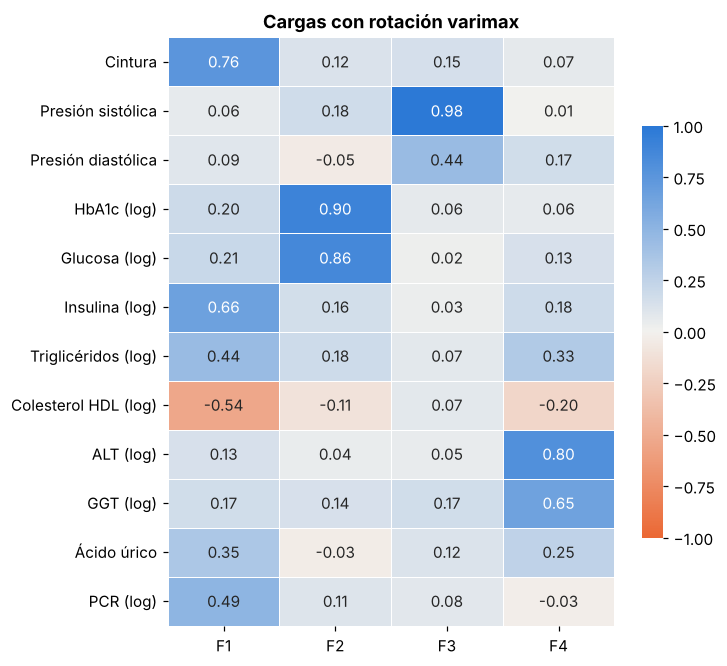

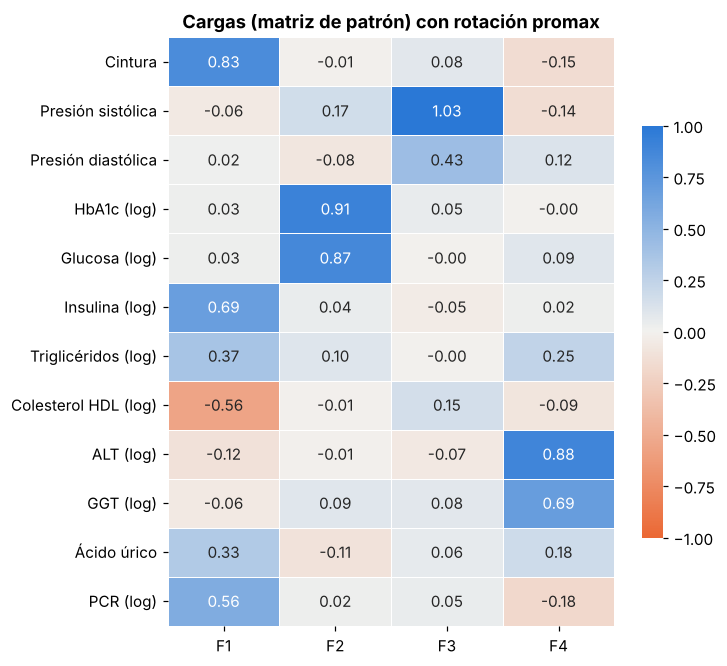

,F1,F2,F3,F4
Cintura,0.83,-0.01,0.08,-0.15
Presión sistólica,-0.06,0.17,1.03,-0.14
Presión diastólica,0.02,-0.08,0.43,0.12
HbA1c (log),0.03,0.91,0.05,-0.00
Glucosa (log),0.03,0.87,-0.00,0.09
Insulina (log),0.69,0.04,-0.05,0.02
Triglicéridos (log),0.37,0.10,-0.00,0.25
Colesterol HDL (log),-0.56,-0.01,0.15,-0.09
ALT (log),-0.12,-0.01,-0.07,0.88
GGT (log),-0.06,0.09,0.08,0.69


In [18]:
# Etiquetas legibles para los gráficos; se indica qué variables están en escala logarítmica
ETIQUETAS = {
    "cintura_cm": "Cintura", "sistolica_mmhg": "Presión sistólica", "diastolica_mmhg": "Presión diastólica",
    "hba1c_pct": "HbA1c", "glucosa_mgdl": "Glucosa", "insulina_uuml": "Insulina",
    "trigliceridos_mgdl": "Triglicéridos", "hdl_mgdl": "Colesterol HDL", "alt_ul": "ALT",
    "ggt_ul": "GGT", "acido_urico_mgdl": "Ácido úrico", "pcr_mgl": "PCR",
}
etiquetas = [ETIQUETAS[v] + (" (log)" if v in VARIABLES_LOG else "") for v in VARIABLES_FINALES]

plot_loadings(L_var, etiquetas, "Cargas con rotación varimax",
              ruta=RUTA_FIGURAS / "05_cargas_varimax.png")
plot_loadings(L_pro, etiquetas, "Cargas (matriz de patrón) con rotación promax",
              ruta=RUTA_FIGURAS / "06_cargas_promax.png")
display(tabla_cargas(L_pro, etiquetas, umbral=0.40))

## 7. Interpretación de los factores

In [19]:
umbral = 0.40
grupos = {}
for j in range(m):
    v = [(etiquetas[i], L_pro[i, j]) for i in range(len(etiquetas))
         if abs(L_pro[i, j]) >= umbral and abs(L_pro[i, j]) == np.abs(L_pro[i]).max()]
    grupos[f"F{j+1}"] = v
    print(f"F{j+1}:", ", ".join(f"{a} ({b:+.2f})" for a, b in sorted(v, key=lambda t: -abs(t[1]))))
sin_asignar = [etiquetas[i] for i in range(len(etiquetas)) if abs(L_pro[i]).max() < umbral]
print("Sin carga ≥ 0.40 en ningún factor:", sin_asignar)

F1: Cintura (+0.83), Insulina (log) (+0.69), PCR (log) (+0.56), Colesterol HDL (log) (-0.56)
F2: HbA1c (log) (+0.91), Glucosa (log) (+0.87)
F3: Presión sistólica (+1.03), Presión diastólica (+0.43)
F4: ALT (log) (+0.88), GGT (log) (+0.69)
Sin carga ≥ 0.40 en ningún factor: ['Triglicéridos (log)', 'Ácido úrico']


| Factor | Nombre | Variables con carga ≥ 0,40 | Variables con carga secundaria |
|---|---|---|---|
| F1 | Adiposidad, resistencia a la insulina e inflamación | Cintura (0,83), insulina (0,69), PCR (0,56), HDL (−0,56) | Triglicéridos (0,37), ácido úrico (0,33) |
| F2 | Glucémico | HbA1c (0,91), glucosa (0,87) | — |
| F3 | Hemodinámico | Presión sistólica (1,03), presión diastólica (0,43) | — |
| F4 | Hepático | ALT (0,88), GGT (0,69) | — |

El primer factor, de adiposidad, resistencia a la insulina e inflamación, agrupa la circunferencia de cintura (0,83), la insulina (0,69), la PCR (0,56) y el colesterol HDL, este último con signo negativo (−0,56); es decir, un puntaje alto en el factor corresponde a un mayor perímetro abdominal, más insulina y PCR, y menos HDL. Esta combinación es coherente con la agrupación de la obesidad abdominal y el HDL bajo dentro del síndrome metabólico (Alberti et al., 2009), con la estrecha relación entre la insulina en ayunas y los demás factores del síndrome de resistencia a la insulina (Meigs et al., 1997) y con la asociación de la PCR, marcador de inflamación sistémica, con dicho síndrome (Ridker et al., 2003). Además, los triglicéridos (0,37) y el ácido úrico (0,33) cargan en este mismo factor, aunque por debajo del umbral de 0,40, por lo que se consideran asociados a él de forma secundaria.

Por su parte, el segundo factor, glucémico, reúne la HbA1c (0,91) y la glucosa en ayunas (0,87), los dos marcadores que se emplean para diagnosticar la prediabetes y la diabetes (ADA, 2025). De este modo, representa el control de la glucosa en sangre, y sus puntajes altos corresponden a valores en los rangos de prediabetes o diabetes. Llama la atención que la insulina no carga en este factor sino en el primero, lo que sugiere que en esta muestra la insulina en ayunas se relaciona más con la adiposidad que con la glucemia; aun así, ambos factores se correlacionan (Φ = 0,35).

El tercer factor, hemodinámico, agrupa la presión sistólica (1,03) y la diastólica (0,43), que reflejan la fuerza que ejerce la sangre sobre las paredes de las arterias (OMS, 2023). Sin embargo, debe interpretarse con cautela, puesto que solo cuenta con dos indicadores y la sistólica presenta un caso Heywood, de modo que el factor queda definido casi por completo por ella. Asimismo, es el factor que menos se correlaciona con los demás (Φ entre 0,08 y 0,31), lo que coincide con Meigs et al. (1997), quienes también encontraron que la presión arterial forma una dimensión distinta de la glucemia y los lípidos.

Finalmente, el cuarto factor, hepático, agrupa la ALT (0,88) y la GGT (0,69), dos enzimas hepáticas que se asocian con el hígado graso no alcohólico. Su correlación con el primer factor es la más alta de la matriz Φ (0,53), lo que es coherente con la estrecha relación entre el hígado graso y el síndrome metabólico (Marchesini et al., 2003). En conjunto, la solución reproduce y amplía la estructura descrita por Meigs et al. (1997): el perfil cardiometabólico no se resume en un único factor, sino en cuatro dimensiones relacionadas entre sí, entre las cuales la de adiposidad, resistencia a la insulina e inflamación ocupa un lugar central, al ser la que más se correlaciona con las demás.

## 8. Confiabilidad por factor (alfa de Cronbach)

In [20]:
Z = (df_final - df_final.mean()) / df_final.std(ddof=1)

filas = []
for f, v in grupos.items():
    items = [a for a, _ in v]
    signos = {a: np.sign(b) for a, b in v}
    sub = pd.DataFrame({a: Z[df_final.columns[etiquetas.index(a)]] * signos[a] for a in items})   # invierte negativos
    filas.append({"Factor": f, "Nº ítems": len(items), "Ítems": ", ".join(items),
                  "α (con inversión)": cronbach_alpha(sub),
                  "α (sin invertir)": cronbach_alpha(pd.DataFrame({a: Z[df_final.columns[etiquetas.index(a)]] for a in items}))})
display(pd.DataFrame(filas).set_index("Factor").round(3))

print("Alfa con las 12 variables juntas (solo como referencia; no forman una sola escala):",
      round(cronbach_alpha(Z), 3))

,Nº ítems,Ítems,α (con inversión),α (sin invertir)
Factor,,,,
F1,4,"Cintura, Insulina (log), Colesterol HDL (log),...",0.719,0.244
F2,2,"HbA1c (log), Glucosa (log)",0.905,0.905
F3,2,"Presión sistólica, Presión diastólica",0.611,0.611
F4,2,"ALT (log), GGT (log)",0.736,0.736


Alfa con las 12 variables juntas (solo como referencia; no forman una sola escala): 0.681


In [21]:
# Correlación ítem-total corregida y alfa al retirar cada ítem en F1, el único factor con más de dos ítems
sub_f1 = pd.DataFrame({a: Z[VARIABLES_FINALES[etiquetas.index(a)]] * np.sign(b) for a, b in grupos["F1"]})
display(pd.DataFrame({
    "Correlación ítem-total": item_total_corr(sub_f1),
    "α si se elimina": alpha_if_dropped(sub_f1),
}).round(3))

# En los factores de dos ítems, el alfa depende solo de la correlación entre ellos: α = 2r / (1 + r)
for f in ["F2", "F3", "F4"]:
    a, b = [VARIABLES_FINALES[etiquetas.index(item)] for item, _ in grupos[f]]
    print(f"{f}: r = {df_final[a].corr(df_final[b]):.3f}")

,Correlación ítem-total,α si se elimina
Cintura,0.637,0.577
Insulina (log),0.583,0.611
Colesterol HDL (log),0.394,0.723
PCR (log),0.430,0.703


F2: r = 0.826
F3: r = 0.440
F4: r = 0.582


Para calcular el alfa de Cronbach, las variables se estandarizan, de modo que ninguna domine la suma por su escala, y se invierten las que cargan con signo negativo. Esto último explica por qué F1 solo alcanza una confiabilidad aceptable cuando se invierte el HDL (α = 0,72 frente a 0,24 sin invertir): como el HDL varía en sentido contrario a las demás variables del factor, sumarlo sin invertir cancela parte de la señal común. En cambio, en los demás factores todas las cargas son positivas, por lo que el alfa es el mismo con o sin inversión.

Según los rangos habituales de interpretación (George & Mallery, 2003), el factor glucémico presenta una confiabilidad excelente (α = 0,91), mientras que el hepático (0,74) y el de adiposidad (0,72) son aceptables y el hemodinámico (0,61) es cuestionable. Cabe señalar que en los factores de dos variables el alfa depende únicamente de la correlación entre ellas (α = 2r / (1 + r)), de modo que el valor de F3 refleja la correlación moderada entre la presión sistólica y la diastólica (r = 0,44) y confirma, junto con el caso Heywood, que se trata del factor más débil. Por su parte, en F1 todas las variables mantienen una correlación ítem-total de al menos 0,39, y solo retirar el HDL aumentaría el alfa, aunque de forma mínima (de 0,719 a 0,723), por lo que se conserva por su relevancia dentro del síndrome metabólico (Alberti et al., 2009).

Por último, el alfa de las doce variables juntas (0,68) se reporta solo como referencia, ya que un alfa moderado no demuestra que las variables formen una sola escala (Cortina, 1993). En consecuencia, la conclusión de que el perfil cardiometabólico no constituye una escala única proviene del análisis factorial, que identificó cuatro dimensiones diferenciadas.

## 9. Validación externa

### 9.1 Puntajes factoriales

In [22]:
# Puntajes por el método de regresión: W = R⁻¹ S, con S = Λ Φ (matriz de estructura de promax)
S = L_pro @ Phi_pro
W = np.linalg.solve(R.values, S)

NOMBRES_FACTORES = ["Adiposidad", "Glucémico", "Hemodinámico", "Hepático"]
puntajes = pd.DataFrame(Z[VARIABLES_FINALES].values @ W, index=df_final.index, columns=NOMBRES_FACTORES)
display(puntajes.describe().round(2))

,Adiposidad,Glucémico,Hemodinámico,Hepático
count,2043.00,2043.00,2043.00,2043.00
mean,0.00,-0.00,-0.00,-0.00
std,0.90,0.95,1.00,0.89
min,-2.33,-1.83,-2.43,-2.16
25%,-0.65,-0.53,-0.71,-0.63
50%,0.00,-0.25,-0.14,-0.12
75%,0.62,0.17,0.51,0.57
max,3.06,5.72,4.70,3.50


Para validar los factores con variables que no intervinieron en su construcción, primero se calcula el puntaje de cada participante en cada factor mediante el método de regresión, que pondera las variables estandarizadas según su relación con cada factor (Tabachnick & Fidell, 2019). Luego, estos puntajes se comparan según el diagnóstico médico de diabetes autorreportado y el grupo de edad, dos variables que no formaron parte del análisis.

### 9.2 Puntajes según el diagnóstico de diabetes

In [23]:
# Diagnóstico autorreportado: 1 = sí, 2 = no; los casos limítrofes y sin respuesta se excluyen
diagnostico_diabetes = df_poblacion.loc[df_final.index, "diabetes_dx"].map(
    {1: "Con diagnóstico", 2: "Sin diagnóstico"}
)
print(diagnostico_diabetes.value_counts(dropna=False))

filas = []
for factor in NOMBRES_FACTORES:
    con = puntajes.loc[diagnostico_diabetes == "Con diagnóstico", factor]
    sin = puntajes.loc[diagnostico_diabetes == "Sin diagnóstico", factor]
    _, p_valor = stats.ttest_ind(con, sin, equal_var=False)
    d_cohen = (con.mean() - sin.mean()) / np.sqrt((con.var(ddof=1) + sin.var(ddof=1)) / 2)
    filas.append({"Factor": factor, "Media con diagnóstico": con.mean(),
                  "Media sin diagnóstico": sin.mean(), "d de Cohen": d_cohen, "p-valor": p_valor})
validacion_diabetes = pd.DataFrame(filas).set_index("Factor")
display(validacion_diabetes.style.format({"p-valor": lambda v: "< 0,001" if v < 0.001 else f"{v:.3f}"}, precision=3))

diabetes_dx
Sin diagnóstico    1625
Con diagnóstico     345
NaN                  73
Name: count, dtype: int64


,Media con diagnóstico,Media sin diagnóstico,d de Cohen,p-valor
Factor,,,,
Adiposidad,0.600,-0.135,0.854,"< 0,001"
Glucémico,1.374,-0.301,1.745,"< 0,001"
Hemodinámico,0.171,-0.047,0.221,"< 0,001"
Hepático,0.283,-0.066,0.400,"< 0,001"


### 9.3 Puntajes según el grupo de edad

In [24]:
grupo_edad = pd.cut(df_poblacion.loc[df_final.index, "edad"], bins=[20, 40, 60, np.inf],
                    right=False, labels=["20 a 39 años", "40 a 59 años", "60 años o más"])

filas = []
for factor in NOMBRES_FACTORES:
    grupos_edad = [puntajes.loc[grupo_edad == g, factor] for g in grupo_edad.cat.categories]
    _, p_valor = stats.f_oneway(*grupos_edad)
    # Eta cuadrado: proporción de la varianza del puntaje explicada por el grupo de edad
    media = puntajes[factor].mean()
    ss_entre = sum(len(g) * (g.mean() - media) ** 2 for g in grupos_edad)
    ss_total = ((puntajes[factor] - media) ** 2).sum()
    filas.append({"Factor": factor, **{c: g.mean() for c, g in zip(grupo_edad.cat.categories, grupos_edad)},
                  "η²": ss_entre / ss_total, "p-valor": p_valor})
validacion_edad = pd.DataFrame(filas).set_index("Factor")
display(validacion_edad.style.format({"p-valor": lambda v: "< 0,001" if v < 0.001 else f"{v:.3f}"}, precision=3))

,20 a 39 años,40 a 59 años,60 años o más,η²,p-valor
Factor,,,,,
Adiposidad,-0.228,0.096,0.099,0.028,"< 0,001"
Glucémico,-0.459,0.045,0.327,0.115,"< 0,001"
Hemodinámico,-0.489,-0.064,0.444,0.147,"< 0,001"
Hepático,-0.172,0.153,0.006,0.021,"< 0,001"


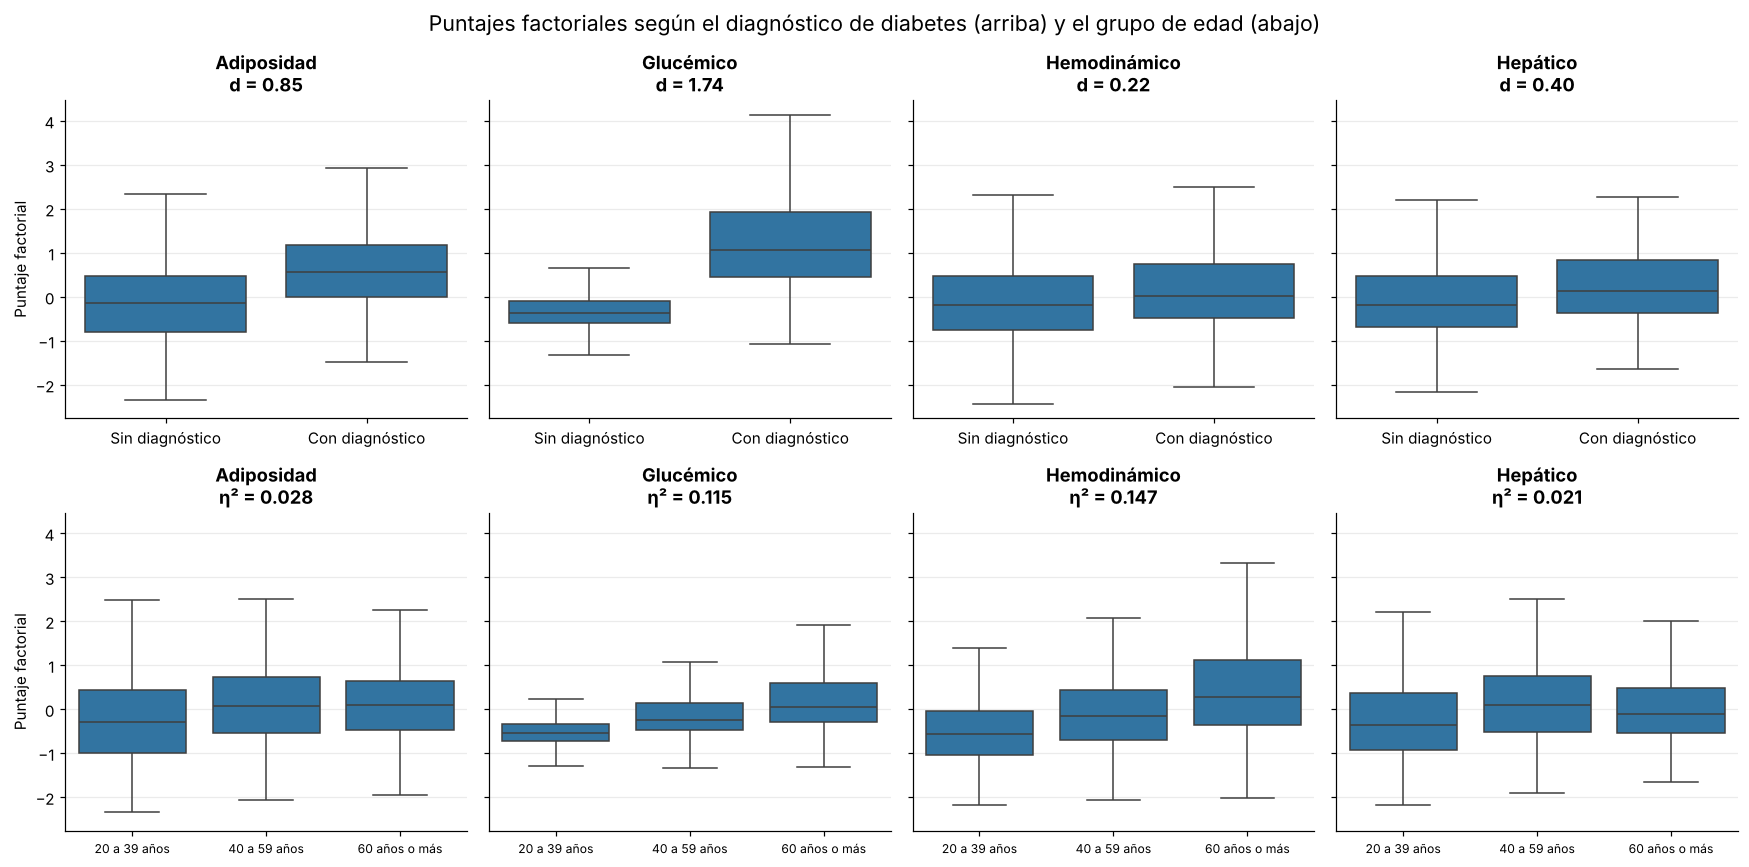

In [25]:
fig, axs = plt.subplots(2, 4, figsize=(16, 8), sharey=True)

for j, factor in enumerate(NOMBRES_FACTORES):
    sns.boxplot(x=diagnostico_diabetes, y=puntajes[factor], order=["Sin diagnóstico", "Con diagnóstico"],
                showfliers=False, ax=axs[0, j])
    axs[0, j].set(title=f"{factor}\nd = {validacion_diabetes.loc[factor, 'd de Cohen']:.2f}", xlabel="", ylabel="")
    sns.boxplot(x=grupo_edad, y=puntajes[factor], showfliers=False, ax=axs[1, j])
    axs[1, j].set(title=f"{factor}\nη² = {validacion_edad.loc[factor, 'η²']:.3f}", xlabel="", ylabel="")
    axs[1, j].tick_params(axis="x", labelsize=8)

axs[0, 0].set_ylabel("Puntaje factorial")
axs[1, 0].set_ylabel("Puntaje factorial")
fig.suptitle("Puntajes factoriales según el diagnóstico de diabetes (arriba) y el grupo de edad (abajo)", fontsize=14)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "07_validacion.png", dpi=150, bbox_inches="tight")
plt.show()

En cuanto al diagnóstico de diabetes, los 345 participantes con diagnóstico presentan puntajes más altos en los cuatro factores que los 1.625 sin diagnóstico (p < 0,001 en todos los casos), mientras que los 73 con respuesta limítrofe o sin respuesta se excluyen de la comparación. Dado que con una muestra de este tamaño incluso diferencias pequeñas resultan significativas, la magnitud se evalúa con la d de Cohen, según la cual la diferencia es muy grande en el factor glucémico (d = 1,74), grande en el de adiposidad (0,85), pequeña a mediana en el hepático (0,40) y pequeña en el hemodinámico (0,22) (Cohen, 1988). Que el factor glucémico sea el que más discrimina es esperable, puesto que la HbA1c y la glucosa son los criterios diagnósticos de la diabetes (ADA, 2025); en cambio, resulta más informativo que el factor de adiposidad, construido sin ningún marcador de glucosa, también muestre una diferencia grande, lo que es coherente con su correlación con el factor glucémico (Φ = 0,35) y con la agrupación de la adiposidad y la insulina dentro del síndrome de resistencia a la insulina (Meigs et al., 1997).

Por su parte, el grupo de edad se asocia sobre todo con los factores hemodinámico (η² = 0,147) y glucémico (η² = 0,115), cuyos puntajes aumentan de forma progresiva desde los 20 a 39 años hasta los 60 años o más, lo que corresponde a efectos grande y mediano, respectivamente (Cohen, 1988). En contraste, el efecto es pequeño en el factor de adiposidad (η² = 0,028), que aumenta entre el primer y el segundo grupo y luego se estabiliza, y en el hepático (η² = 0,021), que alcanza su valor más alto entre los 40 y 59 años. Cabe destacar que el factor hemodinámico, el menos confiable de los cuatro, es el que mejor se diferencia por edad, lo que indica que, pese a sus limitaciones, captura una dimensión con significado propio.

En conjunto, los cuatro factores se relacionan de forma coherente con dos variables que no intervinieron en su construcción, lo que respalda su validez. Además, el comportamiento distinto de cada factor frente a la diabetes y la edad confirma que se trata de dimensiones diferenciadas y no de una sola medida de riesgo.

## 10. Conclusiones

En respuesta a la pregunta guía, las doce mediciones cardiometabólicas de 2.043 adultos de la submuestra en ayunas de NHANES se resumen en cuatro dimensiones latentes: **adiposidad, resistencia a la insulina e inflamación**, **glucémica**, **hemodinámica** y **hepática**. Para llegar a esta solución, se retiraron el colesterol total, por compartir muy poca varianza con las demás variables (MSA = 0,32), y el IMC, por su redundancia con la circunferencia de cintura (r = 0,91), de modo que la matriz depurada cumplió los supuestos del análisis (KMO = 0,71). Además, los criterios de Kaiser y del análisis paralelo coincidieron en retener cuatro factores, que con la extracción por ejes principales explican el 52,6 % de la varianza común y reproducen las correlaciones observadas con un error bajo (RMSR = 0,042).

En cuanto a su estructura, las cuatro dimensiones no son independientes, lo que justificó la rotación promax. En particular, el factor de adiposidad, resistencia a la insulina e inflamación ocupa un lugar central, puesto que es el que más se correlaciona con los demás, en especial con el hepático (Φ = 0,53) y con el glucémico (Φ = 0,35), mientras que el hemodinámico es el más independiente. Este resultado reproduce la estructura descrita por Meigs et al. (1997), en la que los factores de riesgo del síndrome de resistencia a la insulina se organizan en dimensiones diferenciadas, y la amplía con una dimensión hepática, coherente con la relación entre el hígado graso y el síndrome metabólico (Marchesini et al., 2003). Asimismo, en esta muestra la insulina en ayunas se agrupa con la adiposidad y no con la glucemia. En términos de confiabilidad, el factor glucémico es excelente (α = 0,91), el hepático y el de adiposidad son aceptables (0,74 y 0,72) y el hemodinámico es cuestionable (0,61). Por otra parte, los puntajes factoriales mostraron validez externa: las personas con diagnóstico de diabetes puntúan más alto en los cuatro factores, con diferencias grandes en el glucémico (d = 1,74) y en el de adiposidad (d = 0,85), y los factores hemodinámico y glucémico aumentan de forma progresiva con la edad (η² = 0,147 y 0,115).

Estos resultados dan respaldo al planteamiento inicial. Si bien las cuatro dimensiones están relacionadas, se comportan de forma distinta frente a la diabetes y la edad, y son lo suficientemente diferentes como para que una persona presente alteraciones en una de ellas sin presentarlas en las demás, por ejemplo, una adiposidad o un perfil hepático desfavorables con una glucemia todavía normal. Por ello, evaluar cada dimensión por separado, y no solo una medida global de riesgo, permite reconocer en qué componente se concentra el riesgo de cada persona, lo que cobra especial relevancia en alteraciones que avanzan de forma silenciosa, como la hipertensión y la diabetes (ADA, 2025; OMS, 2023).

Finalmente, estas conclusiones deben leerse a la luz de varias limitaciones. En primer lugar, el factor hemodinámico se define con solo dos variables y presenta un caso Heywood en la presión sistólica, que se controló acotando las comunalidades en 1, por lo que su interpretación debe tomarse con cautela. En segundo lugar, los datos son transversales, de manera que el análisis muestra qué marcadores varían en conjunto, pero no en qué orden aparecen las alteraciones. En tercer lugar, el análisis se restringe a la submuestra en ayunas y no incorpora los pesos muestrales, por lo que los resultados describen la muestra analizada y no a la población de Estados Unidos (NCHS, s.f.). En cuarto lugar, el diagnóstico de diabetes usado en la validación es autorreportado, de modo que no incluye los casos no diagnosticados. En quinto lugar, cada marcador corresponde a una sola medición, lo que impide distinguir, por ejemplo, si una PCR mayor que 10 mg/L refleja una inflamación aguda o persistente (Pearson et al., 2003). Por último, la glucosa y la HbA1c conservan cierta asimetría después de la transformación logarítmica, debida a los participantes con valores en rango de diabetes. Como trabajo futuro, la estructura de cuatro factores podría confirmarse en otro ciclo de NHANES mediante un análisis factorial confirmatorio.

## Referencias

Alberti, K. G. M. M., Eckel, R. H., Grundy, S. M., Zimmet, P. Z., Cleeman, J. I., Donato, K. A., Fruchart, J.-C., James, W. P. T., Loria, C. M., & Smith, S. C., Jr. (2009). Harmonizing the metabolic syndrome. *Circulation, 120*(16), 1640–1645. https://doi.org/10.1161/CIRCULATIONAHA.109.192644

American Diabetes Association Professional Practice Committee. (2025). 2. Diagnosis and classification of diabetes: Standards of Care in Diabetes—2025. *Diabetes Care, 48*(Supl. 1), S27–S49. https://doi.org/10.2337/dc25-S002

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.

Cortina, J. M. (1993). What is coefficient alpha? An examination of theory and applications. *Journal of Applied Psychology, 78*(1), 98–104. https://doi.org/10.1037/0021-9010.78.1.98

Fabrigar, L. R., Wegener, D. T., MacCallum, R. C., & Strahan, E. J. (1999). Evaluating the use of exploratory factor analysis in psychological research. *Psychological Methods, 4*(3), 272–299. https://doi.org/10.1037/1082-989X.4.3.272

George, D., & Mallery, P. (2003). *SPSS for Windows step by step: A simple guide and reference. 11.0 update* (4.ª ed.). Allyn & Bacon.

Hirode, G., & Wong, R. J. (2020). Trends in the prevalence of metabolic syndrome in the United States, 2011–2016. *JAMA, 323*(24), 2526–2528. https://doi.org/10.1001/jama.2020.4501

Horn, J. L. (1965). A rationale and test for the number of factors in factor analysis. *Psychometrika, 30*(2), 179–185. https://doi.org/10.1007/BF02289447

Kaiser, H. F. (1974). An index of factorial simplicity. *Psychometrika, 39*(1), 31–36. https://doi.org/10.1007/BF02291575

Marchesini, G., Bugianesi, E., Forlani, G., Cerrelli, F., Lenzi, M., Manini, R., Natale, S., Vanni, E., Villanova, N., Melchionda, N., & Rizzetto, M. (2003). Nonalcoholic fatty liver, steatohepatitis, and the metabolic syndrome. *Hepatology, 37*(4), 917–923. https://doi.org/10.1053/jhep.2003.50161

Meigs, J. B., D'Agostino, R. B., Sr., Wilson, P. W. F., Cupples, L. A., Nathan, D. M., & Singer, D. E. (1997). Risk variable clustering in the insulin resistance syndrome: The Framingham Offspring Study. *Diabetes, 46*(10), 1594–1600.

National Center for Health Statistics. (2020a). *NHANES 2017-2018: Blood pressure (BPX_J)* [Documentación de datos]. Centers for Disease Control and Prevention. https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/BPX_J.htm

National Center for Health Statistics. (2020b). *NHANES 2017-2018: High-sensitivity C-reactive protein (HSCRP_J)* [Documentación de datos]. Centers for Disease Control and Prevention. https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/HSCRP_J.htm

National Center for Health Statistics. (2020c). *NHANES 2017-2018: Insulin (INS_J)* [Documentación de datos]. Centers for Disease Control and Prevention. https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/INS_J.htm

National Center for Health Statistics. (s.f.). *National Health and Nutrition Examination Survey*. Centers for Disease Control and Prevention. https://www.cdc.gov/nchs/nhanes/

Organización Mundial de la Salud. (2023). *Global report on hypertension: The race against a silent killer*. https://www.who.int/publications/i/item/9789240081062

Pearson, T. A., Mensah, G. A., Alexander, R. W., Anderson, J. L., Cannon, R. O., III, Criqui, M., Fadl, Y. Y., Fortmann, S. P., Hong, Y., Myers, G. L., Rifai, N., Smith, S. C., Jr., Taubert, K., Tracy, R. P., & Vinicor, F. (2003). Markers of inflammation and cardiovascular disease: Application to clinical and public health practice. A statement for healthcare professionals from the Centers for Disease Control and Prevention and the American Heart Association. *Circulation, 107*(3), 499–511. https://doi.org/10.1161/01.CIR.0000052939.59093.45

Ridker, P. M., Buring, J. E., Cook, N. R., & Rifai, N. (2003). C-reactive protein, the metabolic syndrome, and risk of incident cardiovascular events: An 8-year follow-up of 14 719 initially healthy American women. *Circulation, 107*(3), 391–397. https://doi.org/10.1161/01.CIR.0000055014.62083.05

SAS Institute Inc. (2011). *SAS/STAT 9.3 user's guide: The FACTOR procedure*. SAS Institute. https://support.sas.com/documentation/cdl/en/statug/63962/HTML/default/statug_factor_sect022.htm

Tabachnick, B. G., & Fidell, L. S. (2019). *Using multivariate statistics* (7.ª ed.). Pearson.

Wang, Q., Würtz, P., Auro, K., Mäkinen, V.-P., Kangas, A. J., Soininen, P., Tiainen, M., Tynkkynen, T., Jokelainen, J., Santalahti, K., Salmi, M., Blankenberg, S., Zeller, T., Viikari, J., Kähönen, M., Lehtimäki, T., Salomaa, V., Perola, M., Jalkanen, S., . . . Ala-Korpela, M. (2016). Metabolic profiling of pregnancy: Cross-sectional and longitudinal evidence. *BMC Medicine, 14*, Artículo 205. https://doi.org/10.1186/s12916-016-0733-0